# Preprocessing user and merchant data


Given Data sturcture:
Part 1: consumer_fraud_probability.csv,
        consumer_user_details.parquet,
        merchant_fraud_probability.csv,
        tbl_consumer.csv,
        tbl_merchants.parquet.
Part 2: Transactions: 20210228 ~ 20210827
Part 3: Transactions: 20210828 ~ 20220227
Part 4: Transactions: 20220228 ~ 20221026

Transactions follows schema:
root
 |-- user_id: long (nullable = true)
 |-- merchant_abn: long (nullable = true)
 |-- dollar_value: double (nullable = true)
 |-- order_id: string (nullable = true)
 |-- order_datetime: date (nullable = true)


order level records.

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder.appName("users Ingest")
    # Parquet + AQE + Broadcast = speed
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.sql.parquet.filterPushdown", "true")
    .config("spark.sql.parquet.enableVectorizedReader", "false")
    .config("spark.sql.files.ignoreCorruptFiles", "true")
    .config("spark.sql.shuffle.partitions", "200")   # tune to cluster size
    .config("spark.sql.repl.eagerEval.enabled", True)
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "Etc/UTC")
    .config('spark.driver.memory', '4g')
    .config('spark.executor.memory', '2g')
    .getOrCreate()
)


spark.conf.set("spark.sql.caseSensitive", "false")
spark

25/10/09 14:07:20 WARN Utils: Your hostname, I-Spider-Spacy-Y.local resolves to a loopback address: 127.0.0.1; using 10.240.65.140 instead (on interface en0)
25/10/09 14:07:20 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/10/09 14:07:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
from pyspark.sql.types import *
from pyspark.sql import functions as F
from pathlib import Path
import pandas as pd


Given Data sturcture:
Part 1: consumer_fraud_probability.csv,
        consumer_user_details.parquet,
        merchant_fraud_probability.csv,
        tbl_consumer.csv,
        tbl_merchants.parquet.
Part 2: Transactions: 20210228 ~ 20210827
Part 3: Transactions: 20210828 ~ 20220227
Part 4: Transactions: 20220228 ~ 20221026

Transactions follows schema:
root
 |-- user_id: long (nullable = true)
 |-- merchant_abn: long (nullable = true)
 |-- dollar_value: double (nullable = true)
 |-- order_id: string (nullable = true)
 |-- order_datetime: date (nullable = true)


order level records.

# Part 1: Read in data files from part 1 folder
Containing 5 files in total:

    consumer_fraud_probability.csv, \
    consumer_user_details.parquet, \
    merchant_fraud_probability.csv, \
    tbl_consumer.csv, \
    tbl_merchants.parquet. 

In [3]:
# ====== [consumer fraud probability] ======
c_fraud_p_df = pd.read_csv("../data/given/part 1/tables/consumer_fraud_probability.csv")
c_fraud_p_df

# Size record
df_shape = c_fraud_p_df.shape
print(f" --- [c_fraud_p_df] size: {df_shape}")
c_fraud_p_df

 --- [c_fraud_p_df] size: (34864, 3)


,user_id,order_datetime,fraud_probability
0,6228,2021-12-19,97.629808
1,21419,2021-12-10,99.247380
2,5606,2021-10-17,84.058250
3,3101,2021-04-17,91.421921
4,22239,2021-10-19,94.703425
...,...,...,...
34859,18466,2022-02-22,8.679873
34860,17552,2021-12-26,8.349463
34861,17875,2021-06-27,8.288847
34862,10401,2021-09-18,8.842216


In [4]:
# ====== [merchant fraud probability] ======
m_fraud_p_df = pd.read_csv("../data/given/part 1/tables/merchant_fraud_probability.csv")
m_fraud_p_df

# Size record
df_shape = m_fraud_p_df.shape
print(f" --- [m_fraud_p_df] size: {df_shape}")
m_fraud_p_df


 --- [m_fraud_p_df] size: (114, 3)


,merchant_abn,order_datetime,fraud_probability
0,19492220327,2021-11-28,44.403659
1,31334588839,2021-10-02,42.755301
2,19492220327,2021-12-22,38.867790
3,82999039227,2021-12-19,94.134700
4,90918180829,2021-09-02,43.325517
...,...,...,...
109,80089686333,2021-09-01,67.505811
110,83220249221,2021-11-27,63.512459
111,85482742429,2021-11-27,70.881311
112,11470993597,2021-09-28,63.377344


In [5]:
# ====== [consumer user detials] ======
c_user_sdf = spark.read.parquet("../data/given/part 1/tables/consumer_user_details.parquet")
c_user_sdf.limit(5)


# Shape record
user_count = c_user_sdf.count()
cols = len(c_user_sdf.columns)
print(f" ---- [c_user_c_user_sdf] Shape: {(user_count, cols)}")


c_user_sdf.limit(5)

 ---- [c_user_c_user_sdf] Shape: (499999, 2)


user_id,consumer_id
1,1195503
2,179208
3,1194530
4,154128
5,712975


#### [Note]: Transactions are on user_id

In [6]:
# ====== [tbl consumer] ======
c_tbl_df = pd.read_csv("../data/given/part 1/tables/tbl_consumer.csv", sep='|')
c_tbl_df

# Size record
df_shape = c_tbl_df.shape
print(f" --- [c_tbl_df] size: {df_shape}")
c_tbl_df

 --- [c_tbl_df] size: (499999, 6)


,name,address,state,postcode,gender,consumer_id
0,Yolanda Williams,413 Haney Gardens Apt. 742,WA,6935,Female,1195503
1,Mary Smith,3764 Amber Oval,NSW,2782,Female,179208
2,Jill Jones MD,40693 Henry Greens,NT,862,Female,1194530
3,Lindsay Jimenez,00653 Davenport Crossroad,NSW,2780,Female,154128
4,Rebecca Blanchard,9271 Michael Manors Suite 651,WA,6355,Female,712975
...,...,...,...,...,...,...
499994,Jessica Avila,508 Miranda Overpass Apt. 218,QLD,4400,Female,1385608
499995,Steven Thornton,7913 Schwartz Mission Suite 483,VIC,3097,Undisclosed,1466964
499996,Christy Smith,5681 Zachary Mountain Apt. 060,NSW,2756,Undisclosed,1253484
499997,Donna Sutton,54140 Jacob Point,VIC,3989,Female,175005


In [7]:
# ====== [tbl merchants] ======
m_tbl_sdf = spark.read.parquet("../data/given/part 1/tables/tbl_merchants.parquet")
m_tbl_sdf.limit(5)


# Size record
merchant_count = m_tbl_sdf.count()
cols = len(m_tbl_sdf.columns)
print(f" ---- [m_tbl_sdf] size: {(merchant_count, cols)}")

print(m_tbl_sdf.head(5))
m_tbl_sdf.limit(5)


 ---- [m_tbl_sdf] size: (4026, 3)
[Row(name='Felis Limited', tags='((furniture, home furnishings and equipment shops, and manufacturers, except appliances), (e), (take rate: 0.18))', merchant_abn=10023283211), Row(name='Arcu Ac Orci Corporation', tags='([cable, satellite, and otHer pay television and radio services], [b], [take rate: 4.22])', merchant_abn=10142254217), Row(name='Nunc Sed Company', tags='([jewelry, watch, clock, and silverware shops], [b], [take rate: 4.40])', merchant_abn=10165489824), Row(name='Ultricies Dignissim Lacus Foundation', tags='([wAtch, clock, and jewelry repair shops], [b], [take rate: 3.29])', merchant_abn=10187291046), Row(name='Enim Condimentum PC', tags='([music shops - musical instruments, pianos, and sheet music], [a], [take rate: 6.33])', merchant_abn=10192359162)]


name,tags,merchant_abn
Felis Limited,"((furniture, home...",10023283211
Arcu Ac Orci Corp...,"([cable, satellit...",10142254217
Nunc Sed Company,"([jewelry, watch,...",10165489824
Ultricies Digniss...,"([wAtch, clock, a...",10187291046
Enim Condimentum PC,([music shops - m...,10192359162


In [8]:
# === Utilities (profile nulls, safe clipping) ===
from pyspark.sql import functions as F

def null_profile(sdf, name="df"):
    total = sdf.count()
    print(f"\n[NULL PROFILE] {name} (rows={total})")
    exprs = [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in sdf.columns]
    row = sdf.agg(*exprs).collect()[0].asDict()
    for c in sdf.columns:
        n = int(row.get(c) or 0)
        pct = (n/total*100) if total else 0
        print(f" - {c:28s}: {n:8d} nulls ({pct:5.2f}%)")

def clip_01(col):
    return F.when(col < 0, 0.0).when(col > 1, 1.0).otherwise(col)


In [9]:
null_profile(c_user_sdf,     "consumer_user_details (raw)")
c_tbl_sdf = spark.createDataFrame(c_tbl_df)
null_profile(c_tbl_sdf,       "tbl_consumer (raw)")
c_fraud_p_sdf = spark.createDataFrame(c_fraud_p_df)
null_profile(c_fraud_p_sdf,   "consumer_fraud_probability (raw)")
null_profile(m_tbl_sdf,      "tbl_merchants (raw)")
m_fraud_p_sdf = spark.createDataFrame(m_fraud_p_df)
null_profile(m_fraud_p_sdf,   "merchant_fraud_probability (raw)")



[NULL PROFILE] consumer_user_details (raw) (rows=499999)
 - user_id                     :        0 nulls ( 0.00%)
 - consumer_id                 :        0 nulls ( 0.00%)


25/10/09 14:07:38 WARN TaskSetManager: Stage 19 contains a task of very large size (2503 KiB). The maximum recommended task size is 1000 KiB.
25/10/09 14:07:39 WARN TaskSetManager: Stage 22 contains a task of very large size (2503 KiB). The maximum recommended task size is 1000 KiB.



[NULL PROFILE] tbl_consumer (raw) (rows=499999)
 - name                        :        0 nulls ( 0.00%)
 - address                     :        0 nulls ( 0.00%)
 - state                       :        0 nulls ( 0.00%)
 - postcode                    :        0 nulls ( 0.00%)
 - gender                      :        0 nulls ( 0.00%)
 - consumer_id                 :        0 nulls ( 0.00%)

[NULL PROFILE] consumer_fraud_probability (raw) (rows=34864)
 - user_id                     :        0 nulls ( 0.00%)
 - order_datetime              :        0 nulls ( 0.00%)
 - fraud_probability           :        0 nulls ( 0.00%)

[NULL PROFILE] tbl_merchants (raw) (rows=4026)
 - name                        :        0 nulls ( 0.00%)
 - tags                        :        0 nulls ( 0.00%)
 - merchant_abn                :        0 nulls ( 0.00%)

[NULL PROFILE] merchant_fraud_probability (raw) (rows=114)
 - merchant_abn                :        0 nulls ( 0.00%)
 - order_datetime              :        

### Null and Missing Data Analysis
We profiled all Part-1 datasets using a Spark `null_profile` function.  

- `consumer_user_details` (499,999 rows): no nulls in `user_id` or `consumer_id`.  
- `tbl_consumer` (499,999 rows): no nulls across demographics (`name, address, state, postcode, gender, consumer_id`).  
- `consumer_fraud_probability` (34,864 rows): no nulls, but only ~20k users have records (≈7% coverage).  
- `tbl_merchants` (4,026 rows): no nulls.  
- `merchant_fraud_probability` (114 rows): no nulls, but only 61 merchants have records (≈3% coverage).  

**Conclusion:** The raw Part-1 data is complete (no nulls), but fraud probability coverage is sparse. We will default missing fraud metrics to 0 in curated tables and note this limitation in analysis.


### Gender Distribution in Consumers
We check how many Male, Female, and Undisclosed entries exist in the `tbl_consumer` data.


In [10]:
# Count gender categories
gender_counts = (
    c_tbl_sdf
    .withColumn("gender_clean", F.lower(F.trim(F.col("gender"))))
    .groupBy("gender_clean")
    .count()
    .orderBy("count", ascending=False)
)
total = c_tbl_sdf.count()
gender_percent = gender_counts.withColumn("percent", (F.col("count")/total*100))
gender_percent.show(truncate=False)


25/10/09 14:07:41 WARN TaskSetManager: Stage 43 contains a task of very large size (2503 KiB). The maximum recommended task size is 1000 KiB.
25/10/09 14:07:41 WARN TaskSetManager: Stage 46 contains a task of very large size (2503 KiB). The maximum recommended task size is 1000 KiB.


+------------+------+------------------+
|gender_clean|count |percent           |
+------------+------+------------------+
|male        |224979|44.99588999177998 |
|female      |224946|44.989289978579954|
|undisclosed |50074 |10.01482002964006 |
+------------+------+------------------+



### Merchant Tags Cleaning and Take Rate Distribution

The `tags` column in `tbl_merchants` encodes three pieces of information:
1. **Primary Category** – the industry or sector the merchant belongs to  
   (e.g., *furniture and home furnishings*, *music shops*).  
2. **Category Code** – a single-letter classification label (e.g., `[a]`, `[b]`, `[e]`).  
3. **Take Rate** – the commission (%) that the BNPL provider earns from transactions with this merchant.  

We parsed `tags` into three separate columns: `primary_category`, `category_code`, and `take_rate`.  
This improves usability for analysis, segmentation, and ranking.

The histogram shows that:

- Most merchants fall between **2% and 7%**, with a strong concentration in the **5–7% range**.  
- Very low take rates (<1%) are rare outliers.  
- The distribution is slightly right-skewed, peaking around 6%.  
- These values are important for ranking merchants, as higher take rates directly increase BNPL revenue.  
- Outliers at the extreme low end will be flagged in preprocessing, but most of the distribution appears valid and usable.  

In [11]:
from pyspark.sql import functions as F

# Clean and parse the tags column
m_tbl_parsed = (
    m_tbl_sdf
    # Make tags lowercase and strip spaces for consistency
    .withColumn("tags_clean", F.lower(F.col("tags")))
    # Extract primary_category (first part before the first closing bracket)
    .withColumn("primary_category", F.regexp_extract("tags_clean", r"\(\[?([^,\]]+.*?)(?:\]|\))", 1))
    # Extract category_code (the single letter in brackets, e.g., [a], [b])
    .withColumn("category_code", F.regexp_extract("tags_clean", r"\[([a-z])\]", 1))
    # Extract take_rate (numeric value after 'take rate:')
    .withColumn("take_rate", F.regexp_extract("tags_clean", r"take rate:\s*([0-9]*\.?[0-9]+)", 1).cast("double"))
)

# Check result
m_tbl_parsed.select("name", "tags", "primary_category", "category_code", "take_rate").show(10, truncate=False)


+------------------------------------+-----------------------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------+-------------+---------+
|name                                |tags                                                                                                             |primary_category                                                                      |category_code|take_rate|
+------------------------------------+-----------------------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------+-------------+---------+
|Felis Limited                       |((furniture, home furnishings and equipment shops, and manufacturers, except appliances), (e), (take rate: 0.18))|(furniture, home furnishings and equipment shops, and ma

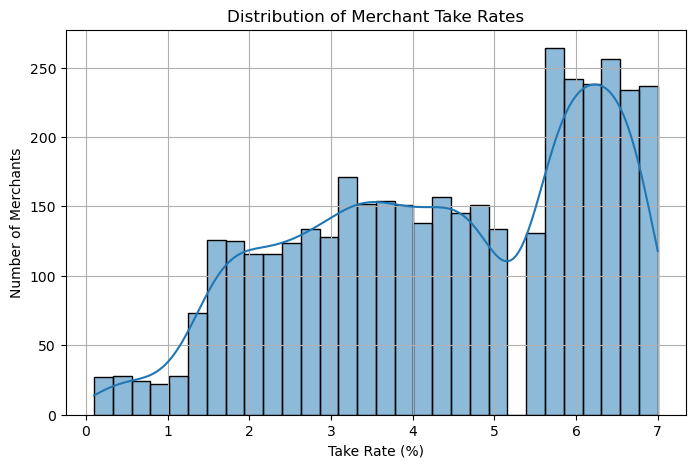

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert to Pandas for plotting
take_rate_pdf = m_tbl_parsed.select("take_rate").toPandas()

plt.figure(figsize=(8,5))
sns.histplot(take_rate_pdf["take_rate"].dropna(), bins=30, kde=True)
plt.xlabel("Take Rate (%)")
plt.ylabel("Number of Merchants")
plt.title("Distribution of Merchant Take Rates")
plt.grid(True)
plt.show()


## Part B: Relate data files
Finding relationships between each datafiles and then find a way to merge them together

In [13]:
# Fields in recorded in each dataframe
print(c_user_sdf.columns)
print(c_fraud_p_df.columns)
print(m_fraud_p_df.columns)
print(c_tbl_df.columns)
print(m_tbl_sdf.columns)

['user_id', 'consumer_id']
Index(['user_id', 'order_datetime', 'fraud_probability'], dtype='object')
Index(['merchant_abn', 'order_datetime', 'fraud_probability'], dtype='object')
Index(['name', 'address', 'state', 'postcode', 'gender', 'consumer_id'], dtype='object')
['name', 'tags', 'merchant_abn']


### Concept 1: user_id & consumer_id

In [14]:


# Check if any user_id maps to multiple consumer_ids
user_multi = c_user_sdf.groupBy("user_id").agg(
    F.countDistinct("consumer_id").alias("unique_consumers")
).filter("unique_consumers > 1")

print("Users with multiple consumer_ids:")
user_multi.show()

# Check if any consumer_id maps to multiple user_ids
consumer_multi = c_user_sdf.groupBy("consumer_id").agg(
    F.countDistinct("user_id").alias("unique_users")
).filter("unique_users > 1")

print("Consumers with multiple user_ids:")
consumer_multi.show()

Users with multiple consumer_ids:


+-------+----------------+
|user_id|unique_consumers|
+-------+----------------+
+-------+----------------+

Consumers with multiple user_ids:
+-----------+------------+
|consumer_id|unique_users|
+-----------+------------+
+-----------+------------+



In [15]:
clean_df = c_user_sdf.filter(
    (F.col("user_id").isNotNull()) & (F.col("consumer_id").isNotNull())
)

# Shape record
rows = clean_df.count()
cols = len(clean_df.columns)
print(f" ---- [clean_df] Shape: {(rows, cols)}")


 ---- [clean_df] Shape: (499999, 2)


### Concept 2: fraud probabiltiy 

In [16]:
# Check if any multiple fraud_probability maped to 1 user_ids
distinct_user_count = len(c_fraud_p_df["user_id"].unique())
print("Number of distinct fraud user_id:", distinct_user_count,
      "out of", user_count, "users")

# Check if any multiple fraud_probability maped to 1 merchant_abn
distinct_user_count = len(m_fraud_p_df["merchant_abn"].unique())
print("Number of distinct fraud merchant_abn:", distinct_user_count, 
      "out of", merchant_count, "merchants") 


Number of distinct fraud user_id: 20128 out of 499999 users
Number of distinct fraud merchant_abn: 61 out of 4026 merchants


In [17]:
# User fraud summary
c_fraud_summary = c_fraud_p_df.groupby("user_id").agg(
    fraud_count=("fraud_probability", "count"),
    avg_fraud_probability=("fraud_probability", "mean")
).reset_index()


print("User fraud summary: [c_fraud_summary] dataframe")
print(c_fraud_summary.head())
print(c_fraud_summary.shape)


# Merchant fraud summary
m_fraud_summary = m_fraud_p_df.groupby("merchant_abn").agg(
    fraud_count=("fraud_probability", "count"),
    avg_fraud_probability=("fraud_probability", "mean")
).reset_index()


print("Merchant fraud summary: [m_fraud_summary] dataframe")
print(m_fraud_summary.head())
print(m_fraud_summary.shape)



User fraud summary: [c_fraud_summary] dataframe
   user_id  fraud_count  avg_fraud_probability
0        1            1               9.805431
1        2            2               9.834682
2        3            1               8.300636
3        4            1               9.633302
4        5            3              15.794925
(20128, 3)
Merchant fraud summary: [m_fraud_summary] dataframe
   merchant_abn  fraud_count  avg_fraud_probability
0   11149063370            3              53.286933
1   11470993597            1              63.377344
2   11590404675            1              29.607818
3   14530561097            1              80.800545
4   14827550074            4              42.000567
(61, 3)


#### Users Fraud Visualisation

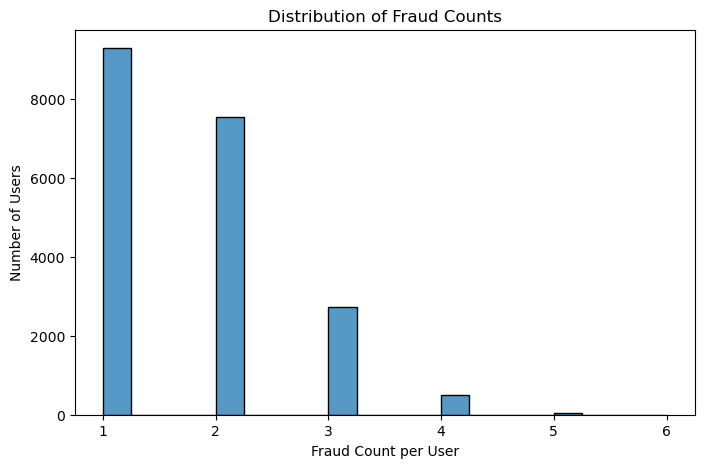

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(c_fraud_summary["fraud_count"], bins=20, kde=False)
plt.xlabel("Fraud Count per User")
plt.ylabel("Number of Users")
plt.title("Distribution of Fraud Counts")
plt.show()


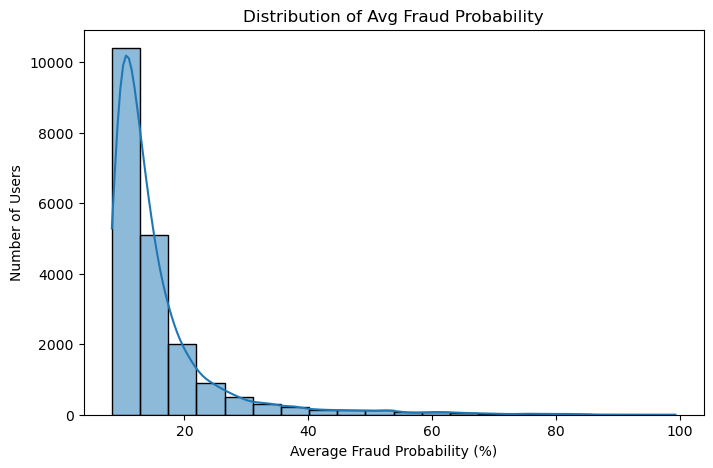

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(c_fraud_summary["avg_fraud_probability"], bins=20, kde=True)
plt.xlabel("Average Fraud Probability (%)")
plt.ylabel("Number of Users")
plt.title("Distribution of Avg Fraud Probability")
plt.show()


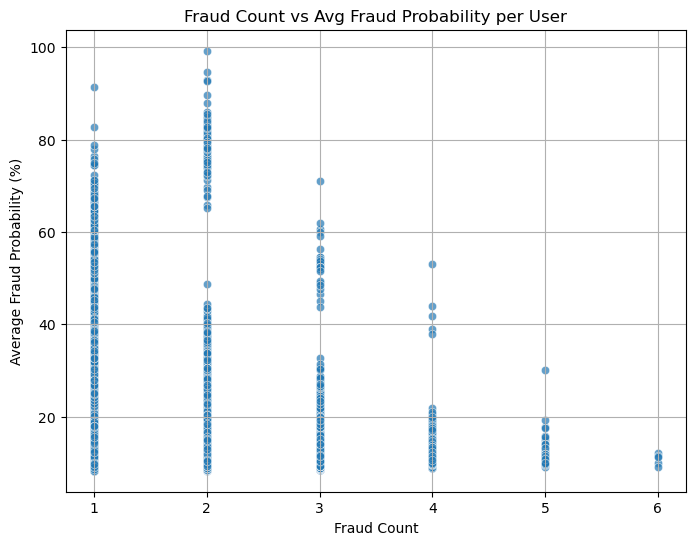

In [20]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    x="fraud_count", 
    y="avg_fraud_probability", 
    data=c_fraud_summary, 
    alpha=0.7
)
plt.xlabel("Fraud Count")
plt.ylabel("Average Fraud Probability (%)")
plt.title("Fraud Count vs Avg Fraud Probability per User")
plt.grid(True)
plt.show()


#### Merchant Fraud Visualisation

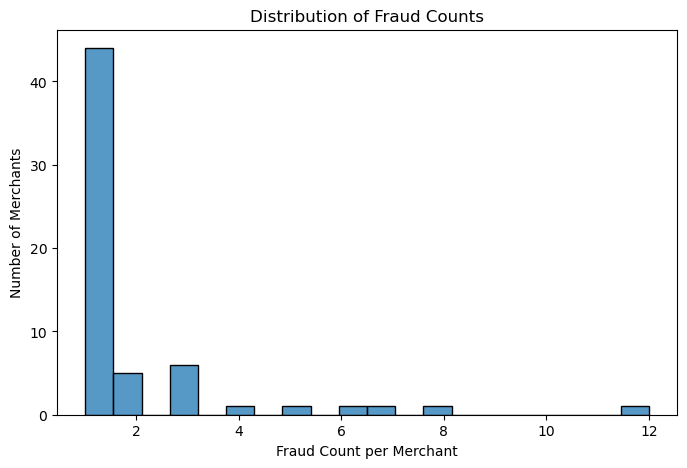

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(m_fraud_summary["fraud_count"], bins=20, kde=False)
plt.xlabel("Fraud Count per Merchant")
plt.ylabel("Number of Merchants")
plt.title("Distribution of Fraud Counts")
plt.show()


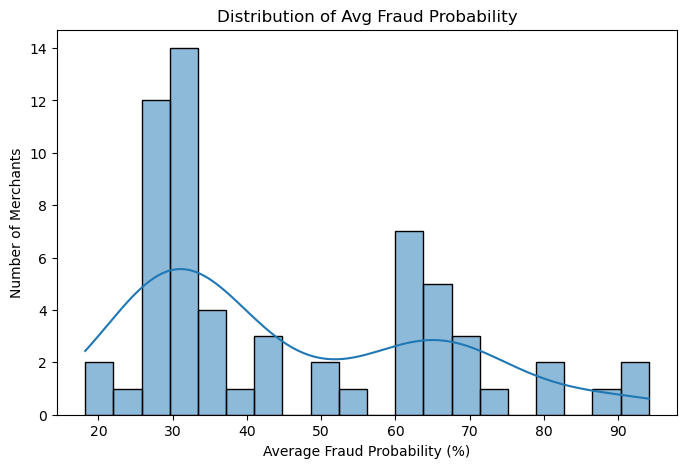

In [22]:
plt.figure(figsize=(8,5))
sns.histplot(m_fraud_summary["avg_fraud_probability"], bins=20, kde=True)
plt.xlabel("Average Fraud Probability (%)")
plt.ylabel("Number of Merchants")
plt.title("Distribution of Avg Fraud Probability")
plt.show()


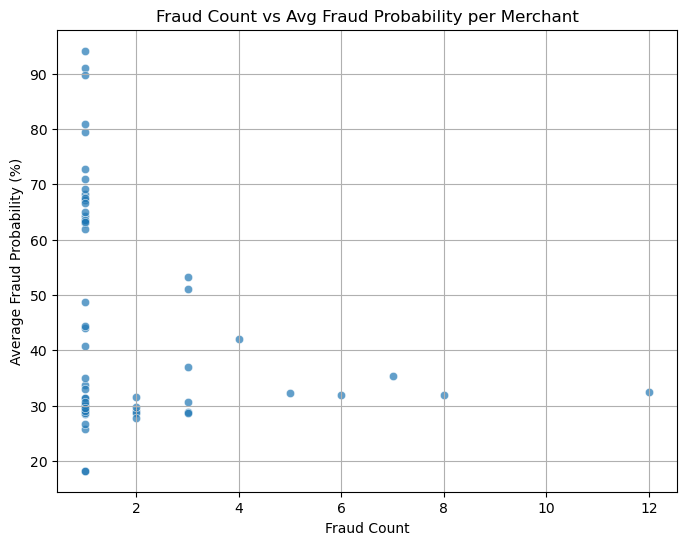

In [23]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    x="fraud_count", 
    y="avg_fraud_probability", 
    data=m_fraud_summary, 
    alpha=0.7
)
plt.xlabel("Fraud Count")
plt.ylabel("Average Fraud Probability (%)")
plt.title("Fraud Count vs Avg Fraud Probability per Merchant")
plt.grid(True)
plt.show()


### Curated Consumer and Merchant Tables

After initial profiling and fraud summaries, we cleaned and consolidated the Part-1 data into two curated datasets:

#### 1. Fraud Probability Scaling
- Original fraud probabilities were recorded on a 0–100 scale.  
- We normalised these values to the 0–1 range by dividing by 100.  
- Out-of-range values (if any) were clipped to remain within [0,1].  
- Aggregated per entity:
  - **Consumers**: fraud_count, avg/max/min fraud_probability per user_id.  
  - **Merchants**: fraud_count, avg/max/min fraud_probability per merchant_abn.  
- Missing fraud records were filled with 0, since only ~7% of consumers and ~3% of merchants had any fraud history.

#### 2. Demographic Cleaning (Consumers)
- **Gender** normalised to three categories: *male*, *female*, *undisclosed*.  
- **State** values converted to consistent 2–3 letter uppercase codes (e.g. `NSW`, `VIC`).  
- **Postcode** values ensured to be four-digit strings (zero-padded where required).  
- Joined with the user ↔ consumer mapping to produce one clean record per consumer.

#### 3. Merchant Tag Parsing
- The `tags` column encodes multiple pieces of information.  
- We extracted:
  - **primary_category**: merchant’s business type.  
  - **category_code**: the single-letter code in brackets.  
  - **take_rate**: commission percentage, parsed as numeric.  
- This makes categories and take rates usable for analysis and ranking.

#### 4. Curated Outputs
- **Consumer Curated Table**:  
  `consumer_id, user_id, demographics (gender, state, postcode), fraud_count, avg/max/min fraud_probability`  

- **Merchant Curated Table**:  
  `merchant_abn, name, primary_category, category_code, take_rate, fraud_count, avg/max/min fraud_probability`  

These curated tables provide clean, standardised inputs for further analysis.  
They can now be linked with transaction records (Parts 2–4) and enriched with ABS postcode data in the next stage of preprocessing.


In [24]:
from pyspark.sql import functions as F

# --- 1. Fraud probability scaling & aggregation ---

# Consumers
c_fraud_agg_sdf = (
    c_fraud_p_sdf
    .withColumn("order_date", F.to_date("order_datetime"))
    .withColumn("fraud_probability", clip_01(F.col("fraud_probability")/100.0))
    .dropna(subset=["user_id"])
    .dropDuplicates(["user_id","order_date"])
    .groupBy("user_id")
    .agg(
        F.count("*").alias("fraud_count"),
        F.avg("fraud_probability").alias("avg_fraud_probability"),
        F.max("fraud_probability").alias("max_fraud_probability"),
        F.min("fraud_probability").alias("min_fraud_probability"),
    )
)

# Merchants
m_fraud_agg_sdf = (
    m_fraud_p_sdf
    .withColumn("order_date", F.to_date("order_datetime"))
    .withColumn("fraud_probability", clip_01(F.col("fraud_probability")/100.0))
    .dropna(subset=["merchant_abn"])
    .dropDuplicates(["merchant_abn","order_date"])
    .groupBy("merchant_abn")
    .agg(
        F.count("*").alias("fraud_count"),
        F.avg("fraud_probability").alias("avg_fraud_probability"),
        F.max("fraud_probability").alias("max_fraud_probability"),
        F.min("fraud_probability").alias("min_fraud_probability"),
    )
)

# --- 2. Clean demographics (consumers) ---

c_tbl_clean_sdf = (
    c_tbl_sdf
    .withColumn("gender", F.lower(F.trim("gender")))          # male, female, undisclosed
    .withColumn("state", F.upper(F.trim("state")))            # ensure uppercase
    .withColumn("postcode", F.lpad(F.regexp_replace(F.col("postcode").cast("string"), r"\D", ""), 4, "0"))  # 4-digit
)

consumer_base_sdf = (
    c_user_sdf
    .join(c_tbl_clean_sdf, on="consumer_id", how="left")
    .select("consumer_id","user_id","name","address","state","postcode","gender")
)

# --- 3. Parse merchant tags (primary_category, category_code, take_rate) ---

m_tbl_parsed = (
    m_tbl_sdf
    .withColumn("tags_clean", F.lower(F.col("tags")))
    .withColumn("primary_category", F.regexp_extract("tags_clean", r"\(\[?([^,\]]+.*?)(?:\]|\))", 1))
    .withColumn("category_code", F.regexp_extract("tags_clean", r"\[([a-z])\]", 1))
    .withColumn("take_rate", F.regexp_extract("tags_clean", r"take rate:\s*([0-9]*\.?[0-9]+)", 1).cast("double"))
)

# --- 4. Curated consumer table ---

consumer_curated = (
    consumer_base_sdf
    .join(c_fraud_agg_sdf, on="user_id", how="left")
    .fillna(
        {
            "fraud_count": 0,
            "avg_fraud_probability": 0.0,
            "max_fraud_probability": 0.0,
            "min_fraud_probability": 0.0,
        }
    )
    .dropDuplicates(["consumer_id","user_id"])
)

print("consumer_curated rows:", consumer_curated.count())
consumer_curated.show(5, truncate=False)

# --- 5. Curated merchant table ---

merchant_curated = (
    m_tbl_parsed
    .join(m_fraud_agg_sdf, on="merchant_abn", how="left")
    .fillna(
        {
            "fraud_count": 0,
            "avg_fraud_probability": 0.0,
            "max_fraud_probability": 0.0,
            "min_fraud_probability": 0.0,
        }
    )
    .select(
        "merchant_abn", "name",
        "primary_category", "category_code", "take_rate",
        "fraud_count", "avg_fraud_probability", "max_fraud_probability", "min_fraud_probability"
    )
    .dropDuplicates(["merchant_abn"])
)

print("merchant_curated rows:", merchant_curated.count())
merchant_curated.show(5, truncate=False)



consumer_curated rows: 499999


25/10/09 14:07:48 WARN TaskSetManager: Stage 79 contains a task of very large size (2503 KiB). The maximum recommended task size is 1000 KiB.


+-------+-----------+--------------+---------------------------+-----+--------+-----------+-----------+---------------------+---------------------+---------------------+
|user_id|consumer_id|name          |address                    |state|postcode|gender     |fraud_count|avg_fraud_probability|max_fraud_probability|min_fraud_probability|
+-------+-----------+--------------+---------------------------+-----+--------+-----------+-----------+---------------------+---------------------+---------------------+
|371406 |7          |James Williams|3709 Mary River            |TAS  |7248    |male       |0          |0.0                  |0.0                  |0.0                  |
|92127  |19         |Dennis Ramirez|20761 Matthews Via Apt. 694|QLD  |4406    |male       |0          |0.0                  |0.0                  |0.0                  |
|166164 |22         |Joseph Turner |4305 White Walks           |NSW  |2281    |male       |0          |0.0                  |0.0                  |0.0

In [25]:
consumer_curated.columns

['user_id',
 'consumer_id',
 'name',
 'address',
 'state',
 'postcode',
 'gender',
 'fraud_count',
 'avg_fraud_probability',
 'max_fraud_probability',
 'min_fraud_probability']

In [26]:
import os

os.makedirs("../data/curated", exist_ok=True)

In [27]:
consumer_curated

25/10/09 14:07:50 WARN TaskSetManager: Stage 105 contains a task of very large size (2503 KiB). The maximum recommended task size is 1000 KiB.
25/10/09 14:07:53 WARN TaskSetManager: Stage 120 contains a task of very large size (2503 KiB). The maximum recommended task size is 1000 KiB.


user_id,consumer_id,name,address,state,postcode,gender,fraud_count,avg_fraud_probability,max_fraud_probability,min_fraud_probability
371406,7,James Williams,3709 Mary River,TAS,7248,male,0,0.0,0.0,0.0
92127,19,Dennis Ramirez,20761 Matthews Vi...,QLD,4406,male,0,0.0,0.0,0.0
166164,22,Joseph Turner,4305 White Walks,NSW,2281,male,0,0.0,0.0,0.0
476081,26,Chloe Walters,04666 Castro Hill,VIC,3026,female,0,0.0,0.0,0.0
286075,29,Evan Pope,1121 Sims Causeway,QLD,4706,undisclosed,0,0.0,0.0,0.0
352250,54,Rebecca Lyons,306 Amber Islands...,QLD,4516,female,0,0.0,0.0,0.0
37181,77,Donald Burgess,52479 Joseph Centers,WA,6017,male,0,0.0,0.0,0.0
356812,167,Traci Smith,35106 Cynthia Haven,NSW,2108,female,0,0.0,0.0,0.0
129911,191,Robert Marshall,9193 Veronica Mea...,NSW,1045,male,0,0.0,0.0,0.0
470093,198,Karen Guerrero,177 Kennedy Viaduct,WA,6005,female,0,0.0,0.0,0.0


In [28]:
pandas_df = consumer_curated.toPandas()
pandas_df.to_csv("../data/curated/consumer_curated.csv")

25/10/09 14:07:55 WARN TaskSetManager: Stage 135 contains a task of very large size (2503 KiB). The maximum recommended task size is 1000 KiB.


In [29]:
pandas_df = merchant_curated.toPandas()
pandas_df.to_csv("../data/curated/merchant_curated.csv")